In [1]:
def run_diffusion_simulation(n_cells=200, n_genes=50, space_size=(1000, 1000),
                             scale_rayleigh=10, exRNA_factor=0.1, ks_thresh=0.05,
                             return_full=False):
    """
    Simulates extracellular RNA diffusion and evaluates Rayleigh fit.

    Parameters
    ----------
    n_cells : int
        Number of simulated cells.
    n_genes : int
        Number of simulated genes.
    space_size : tuple
        Dimensions of spatial area (width, height).
    scale_rayleigh : float
        Scale parameter for Rayleigh distribution.
    exRNA_factor : float
        Fraction of expressed transcripts to place extracellularly.
    ks_thresh : float
        P-value threshold to classify a gene as non-diffusive.
    return_full : bool
        If True, return the full diffusion_stats DataFrame.

    Returns
    -------
    float or (float, DataFrame)
        Proportion of genes classified as non-diffusive, and optionally the full stats.
    """
    import numpy as np
    import pandas as pd

    genes = [f"Gene_{i}" for i in range(n_genes)]

    # 1. Simulate cells
    cell_positions = np.random.uniform(low=0, high=space_size, size=(n_cells, 2))
    expression = np.random.poisson(lam=20, size=(n_cells, n_genes))
    
    cells_df = pd.DataFrame(cell_positions, columns=["x", "y"])
    cells_df["cell_id"] = [f"cell_{i}" for i in range(n_cells)]
    for i, gene in enumerate(genes):
        cells_df[gene] = expression[:, i]

    # 2. Simulate extracellular transcripts
    exRNA_data = []
    for _, cell in cells_df.iterrows():
        cx, cy = cell["x"], cell["y"]
        for gene in genes:
            count = int(cell[gene] * exRNA_factor)
            distances = np.random.rayleigh(scale=scale_rayleigh, size=count)
            angles = np.random.uniform(0, 2 * np.pi, size=count)
            x_offsets = distances * np.cos(angles)
            y_offsets = distances * np.sin(angles)
            for x, y in zip(cx + x_offsets, cy + y_offsets):
                exRNA_data.append({
                    "x": x,
                    "y": y,
                    "gene": gene,
                    "source_cell": cell["cell_id"]
                })

    exRNA_df = pd.DataFrame(exRNA_data)

    # 3. Assess diffusion
    diffusion_stats = assess_diffusion_from_df(exRNA_df, cells_df)
    proportion_non_diffusive = np.sum(diffusion_stats['ks_pval'] < ks_thresh) / diffusion_stats.shape[0]

    return (proportion_non_diffusive, diffusion_stats) if return_full else proportion_non_diffusive


In [3]:
import matplotlib.pyplot as plt

def run_diffusion_simulation(n_cells=200, n_genes=50, space_size=(1000, 1000),
                             scale_rayleigh=10, exRNA_factor=0.1, ks_thresh=0.05,
                             return_full=False, plot=False, max_points=5000):
    """
    Simulates extracellular RNA diffusion and evaluates Rayleigh fit.
    Optionally plots cells and extracellular RNAs.
    """
    import numpy as np
    import pandas as pd

    genes = [f"Gene_{i}" for i in range(n_genes)]

    # 1. Simulate cells
    cell_positions = np.random.uniform(low=0, high=space_size, size=(n_cells, 2))
    expression = np.random.poisson(lam=20, size=(n_cells, n_genes))
    
    cells_df = pd.DataFrame(cell_positions, columns=["x", "y"])
    cells_df["cell_id"] = [f"cell_{i}" for i in range(n_cells)]
    for i, gene in enumerate(genes):
        cells_df[gene] = expression[:, i]

    # 2. Simulate extracellular transcripts
    exRNA_data = []
    for _, cell in cells_df.iterrows():
        cx, cy = cell["x"], cell["y"]
        for gene in genes:
            count = int(cell[gene] * exRNA_factor)
            distances = np.random.rayleigh(scale=scale_rayleigh, size=count)
            angles = np.random.uniform(0, 2 * np.pi, size=count)
            x_offsets = distances * np.cos(angles)
            y_offsets = distances * np.sin(angles)
            for x, y in zip(cx + x_offsets, cy + y_offsets):
                exRNA_data.append({
                    "x": x,
                    "y": y,
                    "gene": gene,
                    "source_cell": cell["cell_id"]
                })

    exRNA_df = pd.DataFrame(exRNA_data)

    # 3. Assess diffusion
    diffusion_stats = assess_diffusion_from_df(exRNA_df, cells_df)
    proportion_non_diffusive = np.sum(diffusion_stats['ks_pval'] < ks_thresh) / diffusion_stats.shape[0]

    # 4. Plot spatial distribution (optional)
    if plot:
        plt.figure(figsize=(8, 8))
        # Plot cells
        plt.scatter(cells_df["x"], cells_df["y"], c="black", s=30, label="Cells", alpha=0.7)

        # Downsample exRNA if too many
        if len(exRNA_df) > max_points:
            exRNA_df = exRNA_df.sample(max_points, random_state=0)

        # Plot exRNA (colored by gene)
        plt.scatter(exRNA_df["x"], exRNA_df["y"], c=pd.factorize(exRNA_df["gene"])[0],
                    cmap="tab20", s=5, alpha=0.6, label="exRNA")

        plt.legend()
        plt.title(f"Spatial Simulation (cells={n_cells}, scale={scale_rayleigh}, exRNA={exRNA_factor})")
        plt.xlim(0, space_size[0])
        plt.ylim(0, space_size[1])
        plt.xlabel("X")
        plt.ylabel("Y")
        plt.show()

    return (proportion_non_diffusive, diffusion_stats) if return_full else proportion_non_diffusive


In [4]:
from scipy import stats
import numpy as np
import pandas as pd

def assess_diffusion_from_df(
    exRNA_df: pd.DataFrame,
    cells_df: pd.DataFrame,
    gene_col: str = "gene",
    source_col: str = "source_cell",
    x_col: str = "x",
    y_col: str = "y"
) -> pd.DataFrame:
    """
    Assess whether extracellular RNA for each gene follows a Rayleigh distribution 
    and compute diffusion-related statistics.

    Parameters
    ----------
    exRNA_df : pd.DataFrame
        DataFrame with extracellular transcripts, containing gene, x, y, and source_cell.
    cells_df : pd.DataFrame
        DataFrame with cell locations (columns: 'cell_id', 'x', 'y').
    gene_col : str
        Column name for gene ID in exRNA_df.
    source_col : str
        Column name for source cell ID in exRNA_df.
    x_col, y_col : str
        Coordinates of extracellular transcript positions.

    Returns
    -------
    pd.DataFrame
        Diffusion assessment results per gene.
    """

    # Merge source cell coordinates into exRNA data
    merged = exRNA_df.merge(
        cells_df[["cell_id", "x", "y"]],
        how="left",
        left_on=source_col,
        right_on="cell_id",
        suffixes=("", "_cell")
    )

    # Compute distance from transcript to its source cell
    merged["distance"] = np.sqrt(
        (merged[x_col] - merged["x_cell"])**2 +
        (merged[y_col] - merged["y_cell"])**2
    )

    results = []

    for gene, group in merged.groupby(gene_col):
        distances = group["distance"].dropna().values
        if len(distances) < 10 or np.sum(distances) == 0:
            continue  # skip underpowered

        # Fit a Rayleigh distribution
        param = stats.rayleigh.fit(distances)

        # Goodness-of-Fit
        ks_stat, ks_pval = stats.kstest(distances, "rayleigh", args=param)
        ad_stat, _, _ = stats.anderson(distances, dist="expon")

        # Likelihood ratio between Rayleigh and KDE
        log_likelihood_rayleigh = np.sum(stats.rayleigh.logpdf(distances, *param))
        log_likelihood_empirical = np.sum(stats.gaussian_kde(distances).logpdf(distances))
        lr_stat = -2 * (log_likelihood_rayleigh - log_likelihood_empirical)

        # Mean displacement as proxy for D
        mean_displacement = np.mean(distances)

        results.append({
            "gene": gene,
            "ks_stat": ks_stat,
            "ks_pval": ks_pval,
            "ad_stat": ad_stat,
            "lr_stat": lr_stat,
            "mean_displacement": mean_displacement
        })

    results_df = pd.DataFrame(results).set_index("gene")
    results_df["-log_ks_pval"] = -np.log(results_df["ks_pval"].clip(lower=1e-300))
    return results_df


In [ ]:
import itertools

# Define ranges of parameters
n_cells_list = [50, 100, 200,400]
scale_list = [5, 10, 20,50]
exrna_factors = [0.05, 0.1, 0.2]

# Generate all combinations of parameters
param_grid = list(itertools.product(n_cells_list, scale_list, exrna_factors))

# Store results
results = []

# Loop over parameter combinations
for n_cells, scale_rayleigh, exRNA_factor in param_grid:
    proportion = run_diffusion_simulation(
        n_cells=n_cells,
        scale_rayleigh=scale_rayleigh,
        exRNA_factor=exRNA_factor,
        return_full=False,plot=True  # Set to True if you want the full DataFrame
    )
    results.append({
        "n_cells": n_cells,
        "scale_rayleigh": scale_rayleigh,
        "exRNA_factor": exRNA_factor,
        "proportion_non_diffusive": proportion
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)
print(results_df)


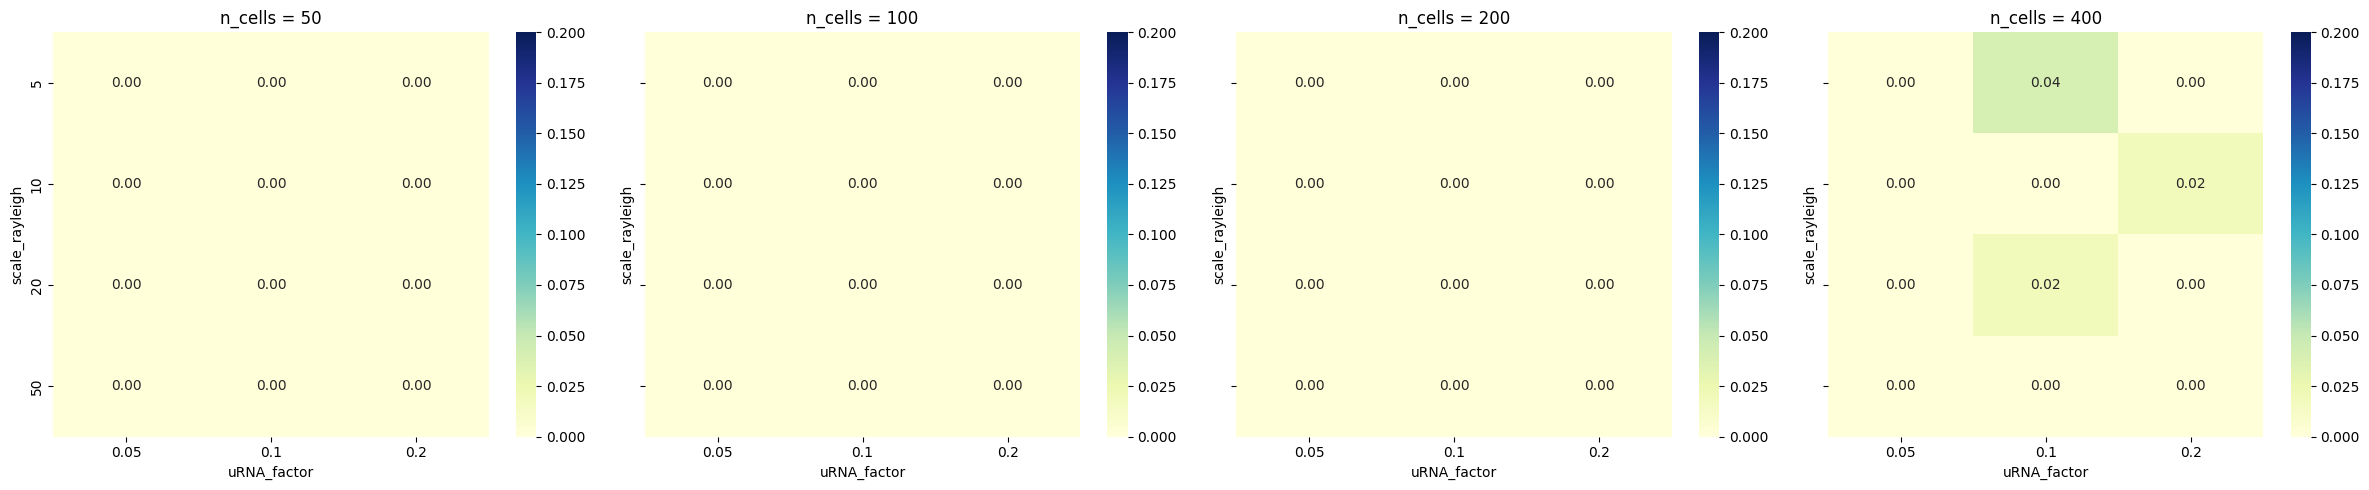

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

n_cells_values = sorted(results_df['n_cells'].unique())
n_subplots = len(n_cells_values)

fig, axes = plt.subplots(1, n_subplots, figsize=(6*n_subplots, 5), sharey=True)

# Determine global min and max for color scale
vmin = results_df['proportion_non_diffusive'].min()
vmax = 0.2

for ax, n_cells in zip(axes, n_cells_values):
    subset = results_df[results_df['n_cells'] == n_cells].pivot(
        index='scale_rayleigh', columns='exRNA_factor', values='proportion_non_diffusive'
    )
    sns.heatmap(subset, annot=True, fmt=".2f", cmap="YlGnBu",
                vmin=vmin, vmax=vmax, ax=ax)
    ax.set_title(f"n_cells = {n_cells}")
    ax.set_xlabel("uRNA_factor")
    ax.set_ylabel("scale_rayleigh")

plt.tight_layout()


plt.show()
